In [1]:
!curl -sSf https://sh.rustup.rs -o rustup-init.sh
!sh rustup-init.sh -y --default-toolchain stable

info: downloading installer
info: profile set to default
info: default host tuple is x86_64-unknown-linux-gnu
info: syncing channel updates for stable-x86_64-unknown-linux-gnu
info: latest update on 2026-09-03 for version 1.98.1 (48a229cea 2026-09-01)
info: downloading 6 components
      rustfmt installed                        2.37 MiB                               rustfmt pending installation             2.37 MiB                               rustfmt pending installation             2.37 MiB                                        rustfmt pending installation             2.37 MiB                          pending installation             2.37 MiB                                            rustfmt pending installation             2.37 MiB                         [5A                               rustfmt pending installation             2.37 MiB                         info: default toolchain set to stable-x86_64-unknown-linux-gnu

  stable-x86_64-unknown-linux-gnu installed - rustc 1.98

In [2]:
import os
os.environ["PATH"] = f"{os.path.expanduser('~/.cargo/bin')}:{os.environ['PATH']}"
!cargo --version

!pip install -q -U pip setuptools wheel
!pip install -q deepfilternet pystoi jiwer soundfile silero-vad pandas matplotlib datasets asteroid

cargo 1.98.1 (797e8a9bc 2026-08-05)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.5 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 32.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
wheel 0.48.0 requires packaging>=24.0, but you have packaging 23.2 which is incompatible.
ray 2.55.1 requires packaging>=24.2, but you have packaging 23.2 which is incompatible.
build 1.5.0 requires packaging>=24.0, b

In [3]:
!pip install -q -U "numpy>=1.26,<2.1" pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
deepfilternet 0.5.6 requires numpy<2.0,>=1.22, but you have numpy 2.0.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.6 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=

In [4]:
import sys, types, time, warnings, string, re, io
warnings.filterwarnings("ignore")
import torch, torchaudio
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio as IPyAudio, display

try:
    from torchaudio.backend.common import AudioMetaData  # noqa: F401
except Exception:
    AM = getattr(torchaudio, "AudioMetaData", None)
    if AM is None:
        from dataclasses import dataclass
        @dataclass
        class AM:
            sample_rate: int = 0
            num_frames: int = 0
            num_channels: int = 0
            bits_per_sample: int = 0
            encoding: str = ""
    backend = types.ModuleType("torchaudio.backend")
    common = types.ModuleType("torchaudio.backend.common")
    common.AudioMetaData = AM
    backend.common = common
    sys.modules["torchaudio.backend"] = backend
    sys.modules["torchaudio.backend.common"] = common
    torchaudio.backend = backend

from df.enhance import enhance, init_df
print("torch", torch.__version__, "| torchaudio", torchaudio.__version__, "| cuda:", torch.cuda.is_available())

torch 2.10.0+cu128 | torchaudio 2.10.0+cu128 | cuda: True


In [5]:
LANG = "hi_in"        # or "ta_in", "te_in", "bn_in", "mr_in", "kn_in", "ml_in", "gu_in", "pa_in", ...
N_SPEECH = 15
N_NOISE  = 10
TEST_SNRS = [15, 5, 0]
TARGET_SR = 16000
OUT_DIR = Path("/kaggle/working/out")
MAX_FILES = 30

DUMMY_DIR  = Path("/kaggle/working/dummy")
CLEAN_DIR2 = DUMMY_DIR / "clean"
NOISE_DIR2 = DUMMY_DIR / "noise_pool"
for d in (CLEAN_DIR2, NOISE_DIR2, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

VARIANTS = {"raw": "raw", "dfn3_full": None, "dfn3_atten12": 12, "dfn3_atten6": 6}

In [6]:
from datasets import load_dataset, Audio

fleurs = load_dataset("google/fleurs", LANG, split="test", streaming=True)
fleurs = fleurs.cast_column("audio", Audio(decode=False))   # skip torchcodec, get raw bytes

refs = {}
for i, ex in enumerate(fleurs):
    if i >= N_SPEECH:
        break
    y, srate = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    stem = f"fleurs_{i:03d}"
    sf.write(CLEAN_DIR2 / f"{stem}.wav", y, srate)
    refs[stem] = ex["transcription"]
pd.DataFrame({"file": list(refs), "text": list(refs.values())}).to_csv(DUMMY_DIR / "refs_clean.csv", index=False)
print(f"{len(refs)} FLEURS ({LANG}) clips downloaded ->", CLEAN_DIR2)

README.md: 0.00B [00:00, ?B/s]

15 FLEURS (hi_in) clips downloaded -> /kaggle/working/dummy/clean


In [7]:
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient
login(UserSecretsClient().get_secret("HF_TOKEN"))   # accept both gated repos' terms on HF first

NOISE_CATS = {"human_non_speech", "phone_signal_alarm", "appliance_machine", "baby_child"}

vaani_noise = load_dataset("ARTPARK-IISc/Vaani-Noise-Event-Dataset", split="train", streaming=True)
vaani_noise = vaani_noise.cast_column("audio", Audio(decode=False))

n = 0
for ex in vaani_noise:
    if n >= N_NOISE:
        break
    cats = set(ex.get("NoiseCategory") or [])
    if not (cats & NOISE_CATS):
        continue
    if ex["audio"]["bytes"] is not None:
        y, srate = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    else:
        y, srate = sf.read(ex["audio"]["path"], dtype="float32")
    tag = "_".join(sorted(cats & NOISE_CATS))
    sf.write(NOISE_DIR2 / f"vaani_{tag}_{n:02d}.wav", y, srate)
    n += 1
print(f"{n} Vaani real-noise clips downloaded ->", NOISE_DIR2)

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/182 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/182 [00:00<?, ?it/s]

10 Vaani real-noise clips downloaded -> /kaggle/working/dummy/noise_pool


In [8]:
def load_wav_any(p):
    y, sr = sf.read(str(p), dtype="float32", always_2d=True)
    return y.mean(axis=1), sr

def snr_mix(clean, noise, snr_db):
    ps, pn = np.mean(clean**2) + 1e-12, np.mean(noise**2) + 1e-12
    return clean + noise * np.sqrt(ps / (pn * 10**(snr_db/10)))

clean_files = sorted(CLEAN_DIR2.glob("*.wav"))
noise_files = list(NOISE_DIR2.glob("*.wav"))
refs_clean = pd.read_csv(DUMMY_DIR / "refs_clean.csv").set_index("file")["text"]
rng2 = np.random.default_rng(1)

NOISY_DIR = DUMMY_DIR / "noisy_input"
NOISY_DIR.mkdir(exist_ok=True)
rows = []

for cf in clean_files:
    c, csr = load_wav_any(cf)
    stem = cf.stem
    others = [f for f in clean_files if f.stem != stem]
    babble_srcs = rng2.choice(len(others), min(3, len(others)), replace=False)
    babble = np.zeros(len(c), dtype=np.float32)
    for k in babble_srcs:
        b, bsr = load_wav_any(others[k])
        b = torchaudio.functional.resample(torch.from_numpy(b), bsr, csr).numpy() if bsr != csr else b
        babble += np.resize(b, len(c))

    nf = noise_files[rng2.integers(len(noise_files))]
    amb, nsr = load_wav_any(nf)
    amb = torchaudio.functional.resample(torch.from_numpy(amb), nsr, csr).numpy() if nsr != csr else amb
    amb = np.resize(amb, len(c))

    for snr in TEST_SNRS:
        mixed = snr_mix(c, 0.6 * babble + 0.4 * amb, snr)
        mixed = mixed / max(1.0, float(np.abs(mixed).max()))
        out_stem = f"{stem}_snr{snr}"
        sf.write(NOISY_DIR / f"{out_stem}.wav", mixed.astype(np.float32), csr)
        rows.append(dict(file=out_stem, text=refs_clean[stem]))

pd.DataFrame(rows).to_csv(DUMMY_DIR / "refs_noisy.csv", index=False)
AUDIO_DIR = NOISY_DIR
REF_CSV   = DUMMY_DIR / "refs_noisy.csv"
MAX_FILES = len(rows)
print(f"{len(rows)} noisy test clips ready at", AUDIO_DIR)

45 noisy test clips ready at /kaggle/working/dummy/noisy_input


In [9]:
model, df_state, _ = init_df()
SR = df_state.sr()
DEVICE = next(model.parameters()).device.type
print("DFN sample rate:", SR, "| device:", DEVICE)
_ = enhance(model, df_state, torch.zeros(1, SR))

2026-09-30 08:48:09 | INFO     | DF | Running on torch 2.10.0+cu128
2026-09-30 08:48:09 | INFO     | DF | Running on host 628b1479e9e4
2026-09-30 08:48:09 | INFO     | DF | Loading model settings of DeepFilterNet3
2026-09-30 08:48:09 | INFO     | DF | Using DeepFilterNet3 model at /root/.cache/DeepFilterNet/DeepFilterNet3
2026-09-30 08:48:10 | INFO     | DF | Initializing model `deepfilternet3`


fatal: not a git repository (or any of the parent directories): .git


2026-09-30 08:48:10 | INFO     | DF | Found checkpoint /root/.cache/DeepFilterNet/DeepFilterNet3/checkpoints/model_120.ckpt.best with epoch 120
2026-09-30 08:48:10 | INFO     | DF | Running on device cuda:0
2026-09-30 08:48:10 | INFO     | DF | Model loaded
DFN sample rate: 48000 | device: cuda


In [10]:
model, df_state, _ = init_df()
SR = df_state.sr()
DEVICE = next(model.parameters()).device.type
print("DFN sample rate:", SR, "| device:", DEVICE)
_ = enhance(model, df_state, torch.zeros(1, SR))

2026-09-30 08:48:13 | INFO     | DF | Loading model settings of DeepFilterNet3
2026-09-30 08:48:13 | INFO     | DF | Using DeepFilterNet3 model at /root/.cache/DeepFilterNet/DeepFilterNet3
2026-09-30 08:48:13 | INFO     | DF | Initializing model `deepfilternet3`
2026-09-30 08:48:13 | INFO     | DF | Found checkpoint /root/.cache/DeepFilterNet/DeepFilterNet3/checkpoints/model_120.ckpt.best with epoch 120
2026-09-30 08:48:13 | INFO     | DF | Running on device cuda:0
2026-09-30 08:48:13 | INFO     | DF | Model loaded
DFN sample rate: 48000 | device: cuda


In [11]:
EXTS = {".wav", ".flac", ".mp3", ".ogg"}

def list_audio(d, n):
    return sorted(p for p in Path(d).rglob("*") if p.suffix.lower() in EXTS)[:n]

def load_mono(path, sr):
    x, s = sf.read(str(path), dtype="float32", always_2d=True)
    t = torch.from_numpy(x.mean(axis=1))
    if s != sr:
        t = torchaudio.functional.resample(t, s, sr)
    return t

def to16k_np(t, sr_in):
    y = torchaudio.functional.resample(t, sr_in, TARGET_SR)
    return np.clip(y.numpy(), -1.0, 1.0)

def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def run_variant(x, name):
    lim = VARIANTS[name]
    if lim == "raw":
        return x, 0.0
    sync(); t0 = time.perf_counter()
    y = enhance(model, df_state, x.unsqueeze(0), atten_lim_db=lim).squeeze(0).cpu()
    sync()
    return y, time.perf_counter() - t0

def dfn3_pass(x16, atten_db=12, sr16=TARGET_SR):
    """Run one waveform (16kHz numpy array) through DFN3, resampling around it."""
    x48 = torchaudio.functional.resample(torch.from_numpy(x16), sr16, SR)
    y48 = enhance(model, df_state, x48.unsqueeze(0), atten_lim_db=atten_db).squeeze(0)
    y16 = torchaudio.functional.resample(y48, SR, TARGET_SR)
    return np.clip(y16.numpy(), -1.0, 1.0)

def agc_pass(x, target_rms=0.1, max_gain=10.0):
    """Simple RMS-based automatic gain control (the 'amplify' stage)."""
    rms = np.sqrt(np.mean(x**2) + 1e-12)
    gain = min(target_rms / rms, max_gain) if rms > 1e-6 else 1.0
    return np.clip(x * gain, -1.0, 1.0)

def si_sdr(est, ref, eps=1e-8):
    est = est - est.mean(); ref = ref - ref.mean()
    alpha = (est * ref).sum() / ((ref ** 2).sum() + eps)
    proj = alpha * ref
    noise = est - proj
    return 10 * np.log10((proj ** 2).sum() / ((noise ** 2).sum() + eps) + eps)

In [12]:
files = list_audio(AUDIO_DIR, MAX_FILES)
print(len(files), "clips found in", AUDIO_DIR)
assert files, "No audio found. Check Cell 7 ran."

rows = []
for f in files:
    x = load_mono(f, SR)
    dur = len(x) / SR
    for name in VARIANTS:
        y, t = run_variant(x, name)
        d = OUT_DIR / name
        d.mkdir(parents=True, exist_ok=True)
        sf.write(d / f"{f.stem}.wav", to16k_np(y, SR), TARGET_SR, subtype="PCM_16")
        rows.append(dict(file=f.stem, variant=name, dur_s=dur, proc_s=t, rtf=(t / dur if t else 0.0)))

timing = pd.DataFrame(rows)
print(timing[timing.variant != "raw"].groupby("variant")["rtf"].agg(["mean", "max"]).round(3))

45 clips found in /kaggle/working/dummy/noisy_input
               mean    max
variant                   
dfn3_atten12  0.008  0.009
dfn3_atten6   0.008  0.009
dfn3_full     0.052  0.287


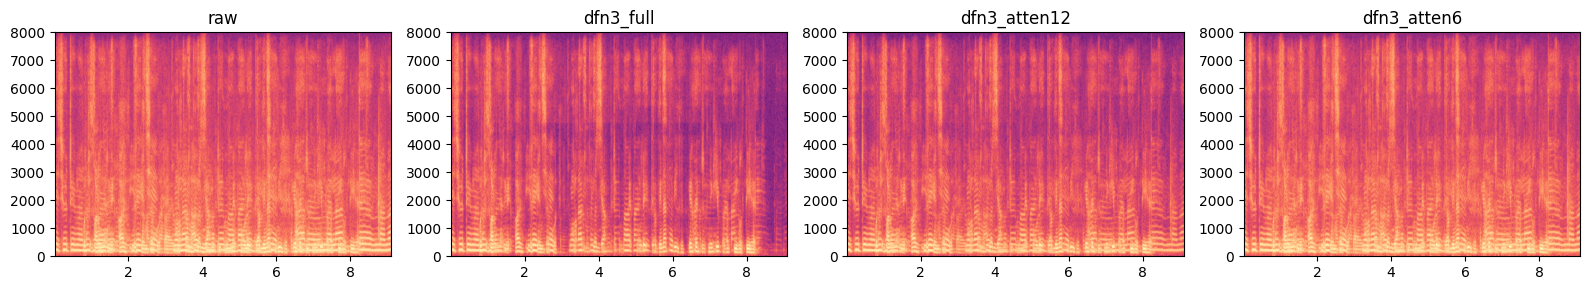

raw


dfn3_full


dfn3_atten12


dfn3_atten6


In [13]:
stem = files[0].stem
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(4 * len(VARIANTS), 3), squeeze=False)
for ax, name in zip(axes[0], VARIANTS):
    w, _ = sf.read(OUT_DIR / name / f"{stem}.wav")
    ax.specgram(w, Fs=TARGET_SR, NFFT=512, noverlap=384, cmap="magma")
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name in VARIANTS:
    print(name)
    display(IPyAudio(str(OUT_DIR / name / f"{stem}.wav")))

In [14]:
import subprocess, tarfile, urllib.request, jiwer

BIN_DIR = Path("/kaggle/working/parakeet_bin")
BIN_DIR.mkdir(exist_ok=True)

PARAKEET_URL = "https://github.com/mudler/parakeet.cpp/releases/download/v0.5.0/parakeet-v0.5.0-bin-linux-cpu-x64.tar.gz"
tar_path = BIN_DIR / "parakeet.tar.gz"
if not any(BIN_DIR.rglob("parakeet-cli")):
    urllib.request.urlretrieve(PARAKEET_URL, tar_path)
    with tarfile.open(tar_path) as tf:
        tf.extractall(BIN_DIR)

CLI_BIN = next(BIN_DIR.rglob("parakeet-cli"))
CLI_BIN.chmod(0o755)
print("parakeet-cli ->", CLI_BIN)

from huggingface_hub import hf_hub_download
GGUF_PATH = hf_hub_download(repo_id="Henil1/Sravaani-1.0-GGUF", filename="sravaani-q8_0.gguf")
print("model ->", GGUF_PATH)

def sravaani_transcribe_one(wav_path):
    fixed = Path("/kaggle/working/_stt_tmp.wav")
    y, sr = sf.read(str(wav_path), dtype="float32", always_2d=True)
    y = y.mean(axis=1)
    if sr != 16000:
        y = torchaudio.functional.resample(torch.from_numpy(y), sr, 16000).numpy()
    sf.write(fixed, y, 16000, subtype="PCM_16")
    result = subprocess.run(
        [str(CLI_BIN), "transcribe", "--model", GGUF_PATH, "--input", str(fixed),
         "--decoder", "tdt", "--threads", "4"],
        capture_output=True, text=True, timeout=120,
    )
    if result.returncode != 0:
        raise RuntimeError(f"parakeet-cli failed on {wav_path}:\n{result.stderr}")
    return result.stdout.strip()

def transcribe(paths):
    return [sravaani_transcribe_one(p) for p in paths]

PUNCT = re.compile("[" + re.escape(string.punctuation + "।॥–—") + "]")
def norm(t):
    return re.sub(r"\s+", " ", PUNCT.sub(" ", str(t).lower())).strip()

def wer_only(ref_t, hyp_t):
    return jiwer.wer(ref_t, hyp_t)

def best_perm_wer(r1, r2, h0, h1):
    a = wer_only(r1, h0) + wer_only(r2, h1)
    b = wer_only(r1, h1) + wer_only(r2, h0)
    return (wer_only(r1, h0), wer_only(r2, h1)) if a <= b else (wer_only(r1, h1), wer_only(r2, h0))

print("SraVaani ready.")

parakeet-cli -> /kaggle/working/parakeet_bin/parakeet-v0.5.0-bin-linux-cpu-x64/parakeet-cli


sravaani-q8_0.gguf:   0%|          | 0.00/660M [00:00<?, ?B/s]

model -> /root/.cache/huggingface/hub/models--Henil1--Sravaani-1.0-GGUF/snapshots/0d36e7ce4136ecd7f7f6caf7f20cba9cec192658/sravaani-q8_0.gguf
SraVaani ready.


In [15]:
ref = pd.read_csv(REF_CSV).set_index("file")["text"]
MED_TERMS = ["paracetamol"]   # your real drug/dosage terms

rows = []
t0 = time.time()
total_files = sum(len([s for s in ref.index if (OUT_DIR / name / f"{s}.wav").exists()]) for name in VARIANTS)
done = 0

for name in VARIANTS:
    stems = [s for s in ref.index if (OUT_DIR / name / f"{s}.wav").exists()]
    print(f"\n[{name}] {len(stems)} files")
    for s in stems:
        h = transcribe([OUT_DIR / name / f"{s}.wav"])[0]
        r, hh = norm(ref[s]), norm(h)
        rows.append(dict(file=s, variant=name, wer=wer_only(r, hh), cer=jiwer.cer(r, hh)))
        done += 1
        elapsed = time.time() - t0
        rate = elapsed / done
        eta = rate * (total_files - done)
        print(f"  [{done}/{total_files}] {s}  wer={rows[-1]['wer']:.2f}  "
              f"elapsed={elapsed:.0f}s  eta={eta:.0f}s")

stt_df = pd.DataFrame(rows)
print("\n=== FINAL RESULTS ===")
print(stt_df.groupby("variant")[["wer", "cer"]].mean().round(3))


[raw] 45 files
  [1/180] fleurs_000_snr15  wer=0.04  elapsed=3s  eta=460s
  [2/180] fleurs_000_snr5  wer=0.29  elapsed=5s  eta=435s
  [3/180] fleurs_000_snr0  wer=1.00  elapsed=7s  eta=420s
  [4/180] fleurs_001_snr15  wer=0.03  elapsed=10s  eta=458s
  [5/180] fleurs_001_snr5  wer=0.50  elapsed=14s  eta=476s
  [6/180] fleurs_001_snr0  wer=1.00  elapsed=17s  eta=486s
  [7/180] fleurs_002_snr15  wer=0.07  elapsed=20s  eta=499s
  [8/180] fleurs_002_snr5  wer=1.00  elapsed=24s  eta=507s
  [9/180] fleurs_002_snr0  wer=1.10  elapsed=27s  eta=512s
  [10/180] fleurs_003_snr15  wer=0.08  elapsed=28s  eta=483s
  [11/180] fleurs_003_snr5  wer=0.58  elapsed=30s  eta=460s
  [12/180] fleurs_003_snr0  wer=1.08  elapsed=31s  eta=439s
  [13/180] fleurs_004_snr15  wer=0.06  elapsed=34s  eta=441s
  [14/180] fleurs_004_snr5  wer=0.06  elapsed=37s  eta=442s
  [15/180] fleurs_004_snr0  wer=0.06  elapsed=40s  eta=444s
  [16/180] fleurs_005_snr15  wer=0.08  elapsed=43s  eta=440s
  [17/180] fleurs_005_snr5  we

In [16]:
OVERLAP_DIR = DUMMY_DIR / "overlap_input"
OVERLAP_DIR.mkdir(exist_ok=True)

clean_files = sorted(CLEAN_DIR2.glob("*.wav"))
refs_clean = pd.read_csv(DUMMY_DIR / "refs_clean.csv").set_index("file")["text"]
assert len(clean_files) >= 2, "Need at least 2 FLEURS clips."

overlap_rows = []
for i in range(0, len(clean_files) - 1, 2):
    f1, f2 = clean_files[i], clean_files[i + 1]
    a, sr1 = sf.read(str(f1), dtype="float32")
    b, sr2 = sf.read(str(f2), dtype="float32")
    if sr1 != TARGET_SR:
        a = torchaudio.functional.resample(torch.from_numpy(a), sr1, TARGET_SR).numpy()
    if sr2 != TARGET_SR:
        b = torchaudio.functional.resample(torch.from_numpy(b), sr2, TARGET_SR).numpy()

    n = min(len(a), len(b))
    mix = a[:n] + b[:n]
    mix = mix / max(1.0, float(np.abs(mix).max()))

    stem = f"{f1.stem}__{f2.stem}"
    sf.write(OVERLAP_DIR / f"{stem}.wav", mix.astype(np.float32), TARGET_SR)
    overlap_rows.append(dict(mix_file=stem, spk1_file=f1.stem, spk1_text=refs_clean[f1.stem],
                             spk2_file=f2.stem, spk2_text=refs_clean[f2.stem]))

overlap_df = pd.DataFrame(overlap_rows)
overlap_df.to_csv(DUMMY_DIR / "overlap_pairs.csv", index=False)
print(f"{len(overlap_df)} overlapping-speaker mixtures ->", OVERLAP_DIR)

7 overlapping-speaker mixtures -> /kaggle/working/dummy/overlap_input


In [17]:
from asteroid.models import BaseModel

sep_model = BaseModel.from_pretrained("JorisCos/ConvTasNet_Libri2Mix_sepclean_16k")
sep_model.eval()
if DEVICE == "cuda":
    sep_model = sep_model.cuda()

def sep_pass(x16):
    t = torch.from_numpy(x16).unsqueeze(0)
    if DEVICE == "cuda":
        t = t.cuda()
    with torch.no_grad():
        out = sep_model.separate(t) if hasattr(sep_model, "separate") else sep_model(t)
    if isinstance(out, tuple):
        out = out[0]
    return out.squeeze(0).cpu().numpy()   # [2, T]

SEP_DIR = DUMMY_DIR / "separated"
SEP_DIR.mkdir(exist_ok=True)

for _, row in overlap_df.iterrows():
    wav, _ = sf.read(str(OVERLAP_DIR / f"{row.mix_file}.wav"), dtype="float32")
    streams = sep_pass(wav)
    for k in range(2):
        sf.write(SEP_DIR / f"{row.mix_file}__out{k}.wav", streams[k].astype(np.float32), TARGET_SR)

print("Separation done ->", SEP_DIR)

pytorch_model.bin:   0%|          | 0.00/20.4M [00:00<?, ?B/s]

Separation done -> /kaggle/working/dummy/separated


In [18]:
rows = []
for _, row in overlap_df.iterrows():
    mix_hyp = norm(transcribe([OVERLAP_DIR / f"{row.mix_file}.wav"])[0])
    h0, h1 = [norm(t) for t in transcribe([SEP_DIR / f"{row.mix_file}__out{k}.wav" for k in range(2)])]
    r1, r2 = norm(row.spk1_text), norm(row.spk2_text)

    rows.append(dict(mix_file=row.mix_file, condition="raw_mixture", speaker="spk1", wer=wer_only(r1, mix_hyp)))
    rows.append(dict(mix_file=row.mix_file, condition="raw_mixture", speaker="spk2", wer=wer_only(r2, mix_hyp)))
    w1, w2 = best_perm_wer(r1, r2, h0, h1)
    rows.append(dict(mix_file=row.mix_file, condition="separated", speaker="spk1", wer=w1))
    rows.append(dict(mix_file=row.mix_file, condition="separated", speaker="spk2", wer=w2))

overlap_wer = pd.DataFrame(rows)
print(overlap_wer.groupby("condition")["wer"].agg(["mean", "median"]).round(3))

              mean  median
condition                 
raw_mixture  0.713   0.782
separated    0.401   0.361


In [19]:
COMBO_DIR = DUMMY_DIR / "combo_input"
COMBO_DIR.mkdir(exist_ok=True)
noise_files = list(NOISE_DIR2.glob("*.wav"))
rng3 = np.random.default_rng(3)

combo_rows = []
for _, row in overlap_df.iterrows():
    mix, msr = load_wav_any(OVERLAP_DIR / f"{row.mix_file}.wav")
    nf = noise_files[rng3.integers(len(noise_files))]
    noise, nsr = load_wav_any(nf)
    if nsr != msr:
        noise = torchaudio.functional.resample(torch.from_numpy(noise), nsr, msr).numpy()
    noise = np.resize(noise, len(mix))

    combo = snr_mix(mix, noise, snr_db=8)
    combo = combo / max(1.0, float(np.abs(combo).max()))
    sf.write(COMBO_DIR / f"{row.mix_file}.wav", combo.astype(np.float32), msr)
    combo_rows.append(row.to_dict())

combo_df = pd.DataFrame(combo_rows)
print(f"{len(combo_df)} combined noisy+overlapping clips ->", COMBO_DIR)

7 combined noisy+overlapping clips -> /kaggle/working/dummy/combo_input


In [20]:
COMBO_OUT = DUMMY_DIR / "combo_out"
for name in ["denoise_then_separate", "separate_then_denoise", "denoise_amplify_separate"]:
    (COMBO_OUT / name).mkdir(parents=True, exist_ok=True)

for _, row in combo_df.iterrows():
    wav, sr = load_wav_any(COMBO_DIR / f"{row.mix_file}.wav")
    if sr != TARGET_SR:
        wav = torchaudio.functional.resample(torch.from_numpy(wav), sr, TARGET_SR).numpy()

    # A: denoise -> separate
    streams_a = sep_pass(dfn3_pass(wav))
    for k in range(2):
        sf.write(COMBO_OUT / "denoise_then_separate" / f"{row.mix_file}__out{k}.wav",
                 streams_a[k].astype(np.float32), TARGET_SR)

    # B: separate -> denoise each stream
    streams_b_raw = sep_pass(wav)
    for k in range(2):
        cleaned = dfn3_pass(streams_b_raw[k])
        sf.write(COMBO_OUT / "separate_then_denoise" / f"{row.mix_file}__out{k}.wav",
                 cleaned.astype(np.float32), TARGET_SR)

    # C: ANC -> amplify -> separate (the pipeline you asked for)
    denoised = dfn3_pass(wav)
    amplified = agc_pass(denoised)
    streams_c = sep_pass(amplified)
    for k in range(2):
        sf.write(COMBO_OUT / "denoise_amplify_separate" / f"{row.mix_file}__out{k}.wav",
                 streams_c[k].astype(np.float32), TARGET_SR)

print("All 3 pipelines done ->", COMBO_OUT)

All 3 pipelines done -> /kaggle/working/dummy/combo_out


In [21]:
rows = []
for _, row in combo_df.iterrows():
    r1, r2 = norm(row.spk1_text), norm(row.spk2_text)

    raw_hyp = norm(transcribe([COMBO_DIR / f"{row.mix_file}.wav"])[0])
    rows.append(dict(mix_file=row.mix_file, pipeline="raw", speaker="spk1", wer=wer_only(r1, raw_hyp)))
    rows.append(dict(mix_file=row.mix_file, pipeline="raw", speaker="spk2", wer=wer_only(r2, raw_hyp)))

    for pipeline in ["denoise_then_separate", "separate_then_denoise", "denoise_amplify_separate"]:
        h0, h1 = [norm(t) for t in transcribe([COMBO_OUT / pipeline / f"{row.mix_file}__out{k}.wav" for k in range(2)])]
        w1, w2 = best_perm_wer(r1, r2, h0, h1)
        rows.append(dict(mix_file=row.mix_file, pipeline=pipeline, speaker="spk1", wer=w1))
        rows.append(dict(mix_file=row.mix_file, pipeline=pipeline, speaker="spk2", wer=w2))

full_wer = pd.DataFrame(rows)
print(full_wer.groupby("pipeline")["wer"].agg(["mean", "median"]).round(3))

                           mean  median
pipeline                               
denoise_amplify_separate  0.703   0.791
denoise_then_separate     0.716   0.765
raw                       0.927   0.987
separate_then_denoise     0.716   0.800


In [22]:
row = combo_df.iloc[0]
print("GROUND TRUTH  spk1:", row.spk1_text)
print("GROUND TRUTH  spk2:", row.spk2_text)

print("\n--- raw ---")
display(IPyAudio(str(COMBO_DIR / f"{row.mix_file}.wav")))
print(transcribe([COMBO_DIR / f"{row.mix_file}.wav"])[0])

for pipeline in ["denoise_then_separate", "separate_then_denoise", "denoise_amplify_separate"]:
    print(f"\n--- {pipeline} ---")
    hyps = transcribe([COMBO_OUT / pipeline / f"{row.mix_file}__out{k}.wav" for k in range(2)])
    for k in range(2):
        display(IPyAudio(str(COMBO_OUT / pipeline / f"{row.mix_file}__out{k}.wav")))
        print(f"  out{k}:", hyps[k])

GROUND TRUTH  spk1: कुछ अणुओं में अस्थिर केंद्रक होता है जिसका मतलब यह है कि उनमें थोड़े या बिना किसी झटके से टूटने की प्रवृत्ति होती है
GROUND TRUTH  spk2: ग्रीनलैंड को बहुत कम जगह बसाया गया था नॉर्स सगास में वे कहते हैं कि एरिक रेड हत्या के लिए आइसलैंड से निर्वासित किया गया था और आगे पश्चिम की यात्रा करते समय ग्रीनलैंड मिला जिसे ग्रीनलैंड नाम दिया गया

--- raw ---


ये चित्र को बहुत कम जगह बताया गया चित्र नॉर्थ सलाह से गेट आइसलैंड भाषण किया गया था

--- denoise_then_separate ---


  out0: ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రం లో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు


  out1: ग्रीनलैंड को बहुत कम जगह बसाया गया था नॉर्थ सदास में वे कहते हैं और एरिक रेड हत्या के लिए आइसलैंड से निर्वाचित किया गया था और आगे

--- separate_then_denoise ---


  out0: ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు


  out1: ग्रीनलैंड को बहुत कम जगह बसाया गया था नॉर्थ सदास में वे कहते है और एरिक ग्रेड हत्या के लिए आइसलैंड से निर्वाचित किया गया था और आगे

--- denoise_amplify_separate ---


  out0: ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రం లో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు


  out1: ग्रीनलैंड को बहुत कम जगह बसाया गया था नॉर्थ सदास में वे कहते हैं और एरिक रेड हत्या के लिए आइसलैंड से निर्वाचित किया गया था और आगे


In [23]:
def process_pipeline(audio_path, verbose=True):
    """
    Production pipeline: noise suppression -> amplify -> speaker separation -> transcribe.
    Returns dict with transcripts, per-stage timing, and total latency.
    """
    timings = {}
    t_start = time.time()

    # load + resample to 16kHz mono
    wav, sr = load_wav_any(audio_path)
    if sr != TARGET_SR:
        wav = torchaudio.functional.resample(torch.from_numpy(wav), sr, TARGET_SR).numpy()
    dur_s = len(wav) / TARGET_SR

    # stage 1: noise suppression (software ANC-equivalent)
    t0 = time.time()
    denoised = dfn3_pass(wav, atten_db=12)
    timings["denoise"] = time.time() - t0

    # stage 2: amplify / normalize
    t0 = time.time()
    amplified = agc_pass(denoised)
    timings["amplify"] = time.time() - t0

    # stage 3: separate speakers
    t0 = time.time()
    streams = sep_pass(amplified)   # shape [2, T]
    timings["separate"] = time.time() - t0

    # stage 4: transcribe each separated stream
    t0 = time.time()
    tmp_paths = []
    for k in range(streams.shape[0]):
        p = Path(f"/kaggle/working/_pipeline_stream{k}.wav")
        sf.write(p, streams[k].astype(np.float32), TARGET_SR)
        tmp_paths.append(p)
    transcripts = transcribe(tmp_paths)
    timings["transcribe"] = time.time() - t0

    timings["total"] = time.time() - t_start
    timings["rtf"] = timings["total"] / dur_s   # >1 means slower than real-time

    if verbose:
        print(f"Input duration: {dur_s:.2f}s")
        for stage, t in timings.items():
            if stage not in ("total", "rtf"):
                print(f"  {stage:12s}: {t:.2f}s")
        print(f"  {'TOTAL':12s}: {timings['total']:.2f}s  (RTF={timings['rtf']:.2f})")
        for k, txt in enumerate(transcripts):
            print(f"\nSpeaker stream {k}: {txt}")

    return dict(transcripts=transcripts, timings=timings, dur_s=dur_s)

In [25]:
# pick any file you have — an overlapping-speaker mix, a noisy clip, or your own recording
result = process_pipeline(COMBO_DIR / f"{combo_df.iloc[0].mix_file}.wav")

Input duration: 9.12s
  denoise     : 0.09s
  amplify     : 0.00s
  separate    : 0.11s
  transcribe  : 4.48s
  TOTAL       : 4.68s  (RTF=0.51)

Speaker stream 0: ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రం లో ఇద్దరు అబ్బాయిలు ఉన్నారు ఈ చిత్రంలో ఇద్దరు అబ్బాయిలు

Speaker stream 1: ग्रीनलैंड को बहुत कम जगह बसाया गया था नॉर्थ सदास में वे कहते हैं और एरिक रेड हत्या के लिए आइसलैंड से निर्वाचित किया गया था और आगे


In [26]:
def rms(x):
    return np.sqrt(np.mean(x**2) + 1e-12)

# Rebuild overlap mixtures with both speakers loudness-matched before summing
OVERLAP_NORM_DIR = DUMMY_DIR / "overlap_input_normalized"
OVERLAP_NORM_DIR.mkdir(exist_ok=True)

norm_rows = []
for i in range(0, len(clean_files) - 1, 2):
    f1, f2 = clean_files[i], clean_files[i + 1]
    a, sr1 = sf.read(str(f1), dtype="float32")
    b, sr2 = sf.read(str(f2), dtype="float32")
    if sr1 != TARGET_SR:
        a = torchaudio.functional.resample(torch.from_numpy(a), sr1, TARGET_SR).numpy()
    if sr2 != TARGET_SR:
        b = torchaudio.functional.resample(torch.from_numpy(b), sr2, TARGET_SR).numpy()

    print(f"{f1.stem}: rms={rms(a):.4f}   {f2.stem}: rms={rms(b):.4f}   ratio={rms(a)/rms(b):.2f}x")

    # match b's loudness to a's, so neither dominates
    b = b * (rms(a) / (rms(b) + 1e-8))

    n = min(len(a), len(b))
    mix = a[:n] + b[:n]
    mix = mix / max(1.0, float(np.abs(mix).max()))

    stem = f"{f1.stem}__{f2.stem}"
    sf.write(OVERLAP_NORM_DIR / f"{stem}.wav", mix.astype(np.float32), TARGET_SR)
    norm_rows.append(dict(mix_file=stem, spk1_file=f1.stem, spk1_text=refs_clean[f1.stem],
                          spk2_file=f2.stem, spk2_text=refs_clean[f2.stem]))

overlap_norm_df = pd.DataFrame(norm_rows)
print(f"\n{len(overlap_norm_df)} loudness-matched mixtures ->", OVERLAP_NORM_DIR)

fleurs_000: rms=0.0419   fleurs_001: rms=0.0974   ratio=0.43x
fleurs_002: rms=0.0415   fleurs_003: rms=0.0149   ratio=2.79x
fleurs_004: rms=0.0461   fleurs_005: rms=0.0865   ratio=0.53x
fleurs_006: rms=0.0154   fleurs_007: rms=0.0436   ratio=0.35x
fleurs_008: rms=0.0585   fleurs_009: rms=0.1035   ratio=0.57x
fleurs_010: rms=0.0520   fleurs_011: rms=0.0016   ratio=32.60x
fleurs_012: rms=0.0686   fleurs_013: rms=0.0520   ratio=1.32x

7 loudness-matched mixtures -> /kaggle/working/dummy/overlap_input_normalized


In [27]:
NORM_SEP_DIR = DUMMY_DIR / "separated_normalized"
NORM_SEP_DIR.mkdir(exist_ok=True)

for _, row in overlap_norm_df.iterrows():
    wav, _ = sf.read(str(OVERLAP_NORM_DIR / f"{row.mix_file}.wav"), dtype="float32")
    streams = sep_pass(wav)
    for k in range(2):
        sf.write(NORM_SEP_DIR / f"{row.mix_file}__out{k}.wav", streams[k].astype(np.float32), TARGET_SR)

print("Separation on loudness-matched mixtures done ->", NORM_SEP_DIR)

Separation on loudness-matched mixtures done -> /kaggle/working/dummy/separated_normalized


In [28]:
rows = []
for _, row in overlap_norm_df.iterrows():
    h0, h1 = [norm(t) for t in transcribe([NORM_SEP_DIR / f"{row.mix_file}__out{k}.wav" for k in range(2)])]
    r1, r2 = norm(row.spk1_text), norm(row.spk2_text)
    w1, w2 = best_perm_wer(r1, r2, h0, h1)
    rows.append(dict(mix_file=row.mix_file, speaker="spk1", wer=w1))
    rows.append(dict(mix_file=row.mix_file, speaker="spk2", wer=w2))
    print(f"{row.mix_file}: spk1_wer={w1:.2f}  spk2_wer={w2:.2f}")

norm_wer_df = pd.DataFrame(rows)
print("\nMean WER (loudness-matched):", norm_wer_df["wer"].mean().round(3))
print("Compare to original 'separated' mean WER: 0.401 (from your earlier overlap_wer table)")

fleurs_000__fleurs_001: spk1_wer=0.17  spk2_wer=0.38
fleurs_002__fleurs_003: spk1_wer=1.00  spk2_wer=0.75
fleurs_004__fleurs_005: spk1_wer=0.39  spk2_wer=0.42
fleurs_006__fleurs_007: spk1_wer=0.46  spk2_wer=0.20
fleurs_008__fleurs_009: spk1_wer=0.57  spk2_wer=0.84
fleurs_010__fleurs_011: spk1_wer=0.36  spk2_wer=0.17
fleurs_012__fleurs_013: spk1_wer=0.11  spk2_wer=0.04

Mean WER (loudness-matched): 0.418
Compare to original 'separated' mean WER: 0.401 (from your earlier overlap_wer table)
